### Spherical spline interpolation
This notebook reconstructs the F3 EEG channel from nearby electrodes (Fp1, F7, C3, and Fz) using spherical spline interpolation based on the Perrin et al. formulation. Electrode positions are normalized onto a unit sphere, and the reconstructed signal is evaluated against the recorded F3 signal using time-domain and frequency-domain metrics.

Run the EEG preprocessing notebook first. The cleaned FIF recordings are expected in Processed_data, and the electrode coordinates in coordinates.csv. The recorded F3 channel is used for evaluating the reconstruction, not as an interpolation input.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.signal import coherence, welch
from scipy.spatial.distance import jensenshannon
from scipy.special import eval_legendre
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mutual_info_score

In [2]:
# Use paths relative to the project directory.
processed_dir = Path("Processed_data")
coordinates_path = Path("coordinates.csv")

# Reconstruct F3 for subjects sub-037 through sub-065.
subjects = range(37, 66)
target_channel = "F3"
neighbors = ["Fp1", "F7", "C3", "Fz"]

# Parameters for the evaluation metrics and spherical spline interpolation.
n_bins = 64
nperseg = 1024
m = 4
n_legendre_terms = 20
regularization_lambda = 1e-5

In [3]:
def normalize_label(label):
    """Standardize electrode labels for coordinate lookup."""
    return str(label).strip().upper()


def load_coordinates(path):
    """Load three-dimensional electrode coordinates from a CSV file."""
    coords_df = pd.read_csv(path, sep=None, engine="python")

    required_cols = ["EEG Label", "X", "Y", "Z"]
    missing_cols = [col for col in required_cols if col not in coords_df.columns]
    if missing_cols:
        raise ValueError(f"Missing columns in coordinate file: {missing_cols}")

    coords = {}
    for _, row in coords_df.iterrows():
        label = normalize_label(row["EEG Label"])
        coords[label] = np.array([
            float(row["X"]),
            float(row["Y"]),
            float(row["Z"]),
        ])

    return coords

In [4]:
coords = load_coordinates(coordinates_path)

# Fz was missing from the original coordinate dataset, so its coordinates
# were calculated separately during the study.
coords["FZ"] = np.array([0.673028145, 0.0, 0.5])

In [5]:
def normalize_vector(vector):
    """Project an electrode position onto the unit sphere."""
    norm = np.linalg.norm(vector)
    if norm == 0:
        raise ValueError("Cannot normalize a zero-length vector.")
    return vector / norm


def spherical_spline_G(cos_theta, m=4, n_terms=20):
    """Evaluate the truncated Legendre series for the spherical spline kernel."""
    g = 0.0
    for n in range(1, n_terms + 1):
        legendre_n = eval_legendre(n, cos_theta)
        numerator = (2 * n + 1) * legendre_n
        denominator = (n ** m) * ((n + 1) ** m)
        g += numerator / denominator
    return g / (4 * np.pi)


def spherical_spline_interpolation(
    data, ch_names, coords, target_channel, available_neighbors,
    m=4, n_terms=20, regularization_lambda=1e-5,
):
    """Reconstruct a channel using a regularized spherical spline kernel."""
    target_label = normalize_label(target_channel)
    neighbor_labels = [normalize_label(ch) for ch in available_neighbors]

    # The target and all neighboring electrodes need known coordinates.
    required_labels = [target_label] + neighbor_labels
    missing_coords = [label for label in required_labels if label not in coords]
    if missing_coords:
        raise ValueError(f"Missing coordinates for channels: {missing_coords}")

    # The recorded target channel is required only for reconstruction evaluation.
    missing_channels = [ch for ch in available_neighbors if ch not in ch_names]
    if target_channel not in ch_names:
        missing_channels.append(target_channel)
    if missing_channels:
        raise ValueError(f"Missing EEG channels: {missing_channels}")

    # Normalize electrode positions to calculate angles on a unit sphere.
    neighbor_xyz = np.array([
        normalize_vector(coords[label]) for label in neighbor_labels
    ])
    target_xyz = normalize_vector(coords[target_label])

    neighbor_indices = [ch_names.index(ch) for ch in available_neighbors]
    neighbor_signals = data[neighbor_indices]
    n_neighbors = len(available_neighbors)

    # Build the kernel matrix from the angular separation of neighboring electrodes.
    G_matrix = np.zeros((n_neighbors, n_neighbors))
    for i in range(n_neighbors):
        for j in range(n_neighbors):
            cos_theta = np.dot(neighbor_xyz[i], neighbor_xyz[j])
            G_matrix[i, j] = spherical_spline_G(
                cos_theta, m=m, n_terms=n_terms
            )

    # Regularization stabilizes the linear system used to calculate the weights.
    G_matrix += regularization_lambda * np.eye(n_neighbors)

    # Evaluate the kernel between F3 and each neighboring electrode.
    g_target = np.zeros(n_neighbors)
    for i in range(n_neighbors):
        cos_theta = np.dot(target_xyz, neighbor_xyz[i])
        g_target[i] = spherical_spline_G(
            cos_theta, m=m, n_terms=n_terms
        )

    weights = np.linalg.solve(G_matrix, g_target)

    # Apply the same spatial weights to every EEG time sample.
    interpolated = np.zeros_like(neighbor_signals[0])
    for weight, signal in zip(weights, neighbor_signals):
        interpolated += weight * signal

    return interpolated

In [6]:
def calculate_metrics(x, y, fs):
    """Compare the recorded and reconstructed EEG signals in time and frequency."""
    # Pearson correlation, its p-value, and RMSE describe time-domain similarity.
    corr, p_value = pearsonr(x, y)
    rmse = np.sqrt(mean_squared_error(x, y))

    # Estimate mutual information after binning each signal into 64 intervals.
    x_binned = np.digitize(x, np.histogram_bin_edges(x, bins=n_bins))
    y_binned = np.digitize(y, np.histogram_bin_edges(y, bins=n_bins))
    mi = mutual_info_score(x_binned, y_binned)

    # Average magnitude-squared coherence over the 1–45 Hz frequency band.
    f_coh, coh = coherence(x, y, fs=fs, nperseg=nperseg)
    coh_mask = (f_coh >= 1) & (f_coh <= 45)
    mean_coherence_1_45 = np.mean(coh[coh_mask])

    # Compare normalized power spectral densities over the same frequency band.
    f_psd, psd_x = welch(x, fs=fs, nperseg=nperseg)
    _, psd_y = welch(y, fs=fs, nperseg=nperseg)
    psd_mask = (f_psd >= 1) & (f_psd <= 45)
    psd_x_band = psd_x[psd_mask]
    psd_y_band = psd_y[psd_mask]

    # A zero-power spectrum cannot be normalized to a probability distribution.
    if psd_x_band.sum() == 0 or psd_y_band.sum() == 0:
        js_distance = np.nan
        js_divergence = np.nan
    else:
        psd_x_norm = psd_x_band / psd_x_band.sum()
        psd_y_norm = psd_y_band / psd_y_band.sum()
        js_distance = jensenshannon(psd_x_norm, psd_y_norm)
        js_divergence = js_distance ** 2

    # Keep original CSV column names for compatibility with the comparison notebook.
    return {
        "Pearsono koreliacija": corr,
        "p reikšmė": p_value,
        "RMSE": rmse,
        "Abipusė informacija": mi,
        "Vidutinė spektrinė koherencija": mean_coherence_1_45,
        "Jensen-Shannon atstumas": js_distance,
        "Jensen-Shannon divergencija": js_divergence,
    }

In [7]:
results = []

for sub in subjects:
    subject_code = f"sub-{sub:03d}"
    fif_path = processed_dir / f"{subject_code}_task-eyesclosed_eeg_cleaned_raw.fif"

    print(f"Processing {subject_code}")

    if not fif_path.exists():
        print(f"File not found: {fif_path}")
        results.append({"subjektas": subject_code, "statusas": "missing_file"})
        continue

    try:
        raw = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)
        data = raw.get_data()
        ch_names = raw.ch_names
        fs = raw.info["sfreq"]

        if target_channel not in ch_names:
            print(f"Channel not found: {target_channel}")
            results.append({"subjektas": subject_code, "statusas": "missing_F3"})
            continue

        available_neighbors = [ch for ch in neighbors if ch in ch_names]
        if len(available_neighbors) < 3:
            print("At least three neighboring channels are required for this analysis.")
            results.append({
                "subjektas": subject_code,
                "statusas": "not_enough_neighbors",
            })
            continue

        # Hold out F3 from interpolation and compare its recorded signal afterward.
        f3_original = data[ch_names.index(target_channel)].copy()
        f3_spherical = spherical_spline_interpolation(
            data=data,
            ch_names=ch_names,
            coords=coords,
            target_channel=target_channel,
            available_neighbors=available_neighbors,
            m=m,
            n_terms=n_legendre_terms,
            regularization_lambda=regularization_lambda,
        )

        metrics = calculate_metrics(f3_original, f3_spherical, fs)
        results.append({
            "subjektas": subject_code,
            "statusas": "ok",
            "Interpoliuojamas kanalas": target_channel,
            "Kaimyniniai kanalai": ",".join(available_neighbors),
            "Kaimynų skaičius": len(available_neighbors),
            "Spline m": m,
            "Ležanro polinomai n": n_legendre_terms,
            "fs": fs,
            **metrics,
        })

        print(
            f"OK | corr={metrics['Pearsono koreliacija']:.4f}, "
            f"RMSE={metrics['RMSE']:.6e}, "
            f"JSD={metrics['Jensen-Shannon divergencija']:.6f}"
        )

    except Exception as error:
        print(f"Error for {subject_code}: {error}")
        results.append({
            "subjektas": subject_code,
            "statusas": f"error: {error}",
        })

Processing sub-037
OK | corr=0.8006, RMSE=4.249510e-06, JSD=0.011921
Processing sub-038
OK | corr=0.6380, RMSE=3.969622e-06, JSD=0.012642
Processing sub-039
OK | corr=0.6944, RMSE=6.758248e-06, JSD=0.013578
Processing sub-040
OK | corr=0.4289, RMSE=7.799853e-06, JSD=0.010728
Processing sub-041
OK | corr=0.9285, RMSE=1.805543e-06, JSD=0.001007
Processing sub-042
OK | corr=0.2970, RMSE=9.366475e-06, JSD=0.049684
Processing sub-043
OK | corr=0.5618, RMSE=3.345580e-06, JSD=0.002965
Processing sub-044
OK | corr=0.9064, RMSE=2.680598e-06, JSD=0.005499
Processing sub-045
OK | corr=0.7689, RMSE=3.299799e-06, JSD=0.004524
Processing sub-046
OK | corr=0.8497, RMSE=4.243423e-06, JSD=0.007109
Processing sub-047
OK | corr=0.7508, RMSE=3.902527e-06, JSD=0.014315
Processing sub-048
OK | corr=0.4976, RMSE=7.660526e-06, JSD=0.100066
Processing sub-049
OK | corr=0.8139, RMSE=3.530491e-06, JSD=0.005368
Processing sub-050
OK | corr=0.4165, RMSE=8.786362e-06, JSD=0.073924
Processing sub-051
OK | corr=-0.14

In [8]:
results_df = pd.DataFrame(results)
display(results_df)

# Save the subject-level metrics for comparison with other methods.
output_csv = processed_dir / "F3_spherical_spline_metrics_all_subjects.csv"
results_df.to_csv(output_csv, index=False, encoding="utf-8-sig")
print(f"Results saved to: {output_csv}")

,subjektas,statusas,Interpoliuojamas kanalas,Kaimyniniai kanalai,Kaimynų skaičius,Spline m,Ležanro polinomai n,fs,Pearsono koreliacija,p reikšmė,RMSE,Abipusė informacija,Vidutinė spektrinė koherencija,Jensen-Shannon atstumas,Jensen-Shannon divergencija
0,sub-037,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.800577,0.0,0.000004,0.518439,0.316986,0.109182,0.011921
1,sub-038,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.638045,0.0,0.000004,0.275149,0.463269,0.112435,0.012642
2,sub-039,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.694427,0.0,0.000007,0.332011,0.440033,0.116523,0.013578
3,sub-040,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.428908,0.0,0.000008,0.260653,0.429185,0.103576,0.010728
4,sub-041,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.928524,0.0,0.000002,0.961208,0.854078,0.031731,0.001007
5,sub-042,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.296976,0.0,0.000009,0.442973,0.381244,0.222899,0.049684
6,sub-043,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.561838,0.0,0.000003,0.210648,0.362181,0.054453,0.002965
7,sub-044,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.906423,0.0,0.000003,0.849318,0.723384,0.074157,0.005499
8,sub-045,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.768900,0.0,0.000003,0.548124,0.660758,0.067258,0.004524
9,sub-046,ok,F3,"Fp1,F7,C3,Fz",4,4,20,500.0,0.849730,0.0,0.000004,0.665500,0.475168,0.084315,0.007109


Results saved to: C:\Users\gytis\Baigiamasis\Processed_data\F3_spherical_spline_metrics_all_subjects.csv


### Optional reconstruction visualizations
Plot the recorded and spherical spline-reconstructed F3 signals for subject sub-059 over the original 0–40 s interval. The power spectral density (PSD) comparison uses the same reconstructed signal.

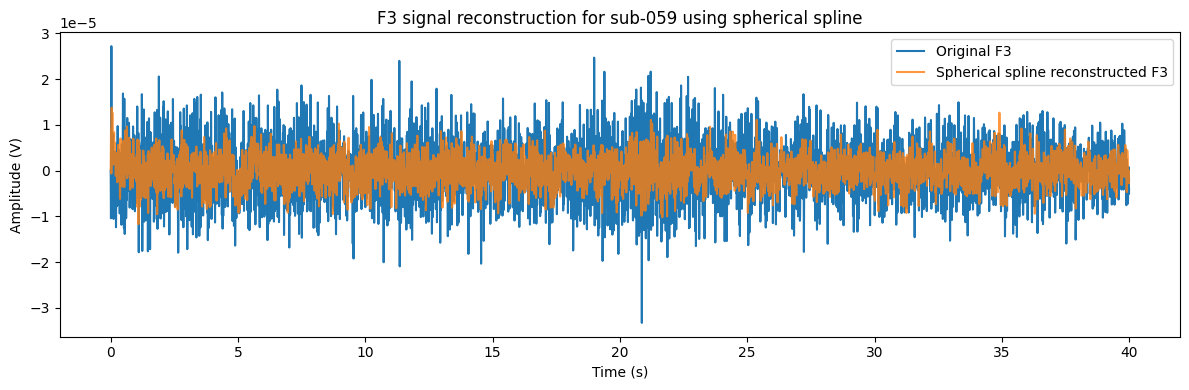

In [9]:
subject_to_plot = "sub-059"
preview_path = processed_dir / f"{subject_to_plot}_task-eyesclosed_eeg_cleaned_raw.fif"

if preview_path.exists():
    raw = mne.io.read_raw_fif(preview_path, preload=True, verbose=False)
    data = raw.get_data()
    ch_names = raw.ch_names
    fs = raw.info["sfreq"]

    available_neighbors = [ch for ch in neighbors if ch in ch_names]
    f3_original = data[ch_names.index(target_channel)]

    # Use the same spherical spline parameters as in the metrics calculation.
    f3_spherical = spherical_spline_interpolation(
        data=data,
        ch_names=ch_names,
        coords=coords,
        target_channel=target_channel,
        available_neighbors=available_neighbors,
        m=m,
        n_terms=n_legendre_terms,
        regularization_lambda=regularization_lambda,
    )

    start_sec = 0
    end_sec = 40
    start = int(start_sec * fs)
    end = int(end_sec * fs)
    time = np.arange(start, end) / fs

    plt.figure(figsize=(12, 4))
    plt.plot(time, f3_original[start:end], label="Original F3")
    plt.plot(time, f3_spherical[start:end], label="Spherical spline reconstructed F3", alpha=0.8)
    plt.title(f"F3 signal reconstruction for {subject_to_plot} using spherical spline")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude (V)")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"Preview file not found: {preview_path}")